# Smartphone Battery & Academic Performance - EDA Assignment 2 (Team 6)

**Goal:** explore how smartphone usage and battery/charging habits relate to students' academic performance (CGPA), then compare simple machine-learning models and rank the most important features.

**Data:** synthetic survey data for 60 students (randomly generated with a fixed seed, plus deliberately injected errors). The notebook is self-contained, so use **Runtime > Run all** in Colab.

**Outline:** 1) Generate raw data, 2) Inspect problems, 3) Clean, 4) EDA and visualizations, 5) Statistical tests, 6) Model comparison, 7) Feature importance, 8) Conclusions

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")

## 1. Generate Random (Synthetic) Data

In [2]:
rng = np.random.default_rng(42)
n = 60
ids    = [f"S{i:03d}" for i in range(1, n + 1)]
age    = rng.integers(17, 25, n)
gender = rng.choice(["Male", "Female"], n)
year   = np.clip(age - 16, 1, 4)
screen = np.clip(rng.normal(5.5, 1.8, n), 1.5, 11).round(1)
charges = np.clip((screen / 2.2 + rng.normal(1.2, .6, n)).round(), 1, 6).astype(int)
battery = np.clip(rng.normal(86, 8, n), 60, 100).round(0).astype(int)
night  = rng.choice([0, 1], n, p=[.55, .45])
study  = np.clip(rng.normal(3.5, 1.3, n) - 0.15 * (screen - 5.5), 0.5, 8).round(1)
attend = np.clip(rng.normal(82, 9, n) - 0.8 * (screen - 5.5), 50, 100).round(0).astype(int)
cgpa   = np.clip(6.5 + 0.45 * study - 0.18 * (screen - 5.5) - 0.25 * night
                 + 0.012 * (attend - 80) + rng.normal(0, .45, n), 3, 10).round(2)

clean0 = pd.DataFrame({
    "student_id": ids, "age": age, "gender": gender, "year_of_study": year,
    "daily_screen_time_hrs": screen, "daily_charge_cycles": charges,
    "battery_health_pct": battery,
    "charges_overnight": np.where(night == 1, "Yes", "No"),
    "daily_study_hrs": study, "attendance_pct": attend, "cgpa": cgpa})

# ---- make it messy (this is the RAW data) ----
raw = clean0.copy().astype(object)
raw["gender"] = [rng.choice([g, g.lower(), g[0], g.upper() + " "]) for g in raw["gender"]]
raw["charges_overnight"] = [rng.choice([v, v.lower(), "Y" if v == "Yes" else "N"]) for v in raw["charges_overnight"]]
raw["daily_screen_time_hrs"] = [f"{v} hrs" if rng.random() < .1 else v for v in raw["daily_screen_time_hrs"]]
raw["battery_health_pct"]    = [f"{v}%" if rng.random() < .15 else v for v in raw["battery_health_pct"]]
for col, k in [("daily_screen_time_hrs", 4), ("battery_health_pct", 3), ("daily_study_hrs", 3),
               ("cgpa", 3), ("attendance_pct", 3), ("age", 2)]:
    for i in rng.choice(n, k, replace=False):
        raw.loc[i, col] = np.nan                       # missing values
raw.loc[7, "daily_screen_time_hrs"] = 45.0              # outlier
raw.loc[21, "battery_health_pct"]   = 250               # impossible
raw.loc[33, "cgpa"]                 = 14.2              # above 10 scale
raw.loc[48, "age"]                  = 2                 # typo
raw = pd.concat([raw, raw.iloc[[5, 17, 40]]], ignore_index=True)   # duplicates
raw = raw.sample(frac=1, random_state=1).reset_index(drop=True)

print("RAW DATA:", raw.shape)
display(raw.head(10))

RAW DATA: (63, 11)


,student_id,age,gender,year_of_study,daily_screen_time_hrs,daily_charge_cycles,battery_health_pct,charges_overnight,daily_study_hrs,attendance_pct,cgpa
0,S025,23,FEMALE,4,4.8,2,87%,N,3.7,81,8.06
1,S040,22,Male,4,3.7,3,97,N,4.6,84,9.1
2,S052,18,female,2,2.4,2,84,yes,4.5,81,7.91
3,S028,23,M,4,6.4,4,86,No,1.8,77,7.3
4,S018,18,M,2,6.7,4,79,Yes,5.6,89,8.84
5,S003,22,M,4,2.5,2,96,Y,3.6,94,8.45
6,S022,19,MALE,3,4.9,5,250,N,4.2,90,NaN
7,S043,22,FEMALE,4,4.8,3,84,No,3.6,89,8.39
8,S042,23,MALE,4,3.9,2,80,no,2.4,87,8.89
9,S045,17,Female,1,4.9,5,87,N,2.7,89,8.42


## 2. Inspect Problems In Raw Data


Duplicate rows: 3
Gender values: <StringArray>
['FEMALE ', 'Male', 'female', 'M', 'MALE ', 'Female', 'male', 'F']
Length: 8, dtype: str
Overnight values: <StringArray>
['N', 'yes', 'No', 'Yes', 'Y', 'no']
Length: 6, dtype: str

Missing values:
 age                      2
daily_screen_time_hrs    4
battery_health_pct       3
daily_study_hrs          3
attendance_pct           3
cgpa                     3
dtype: int64


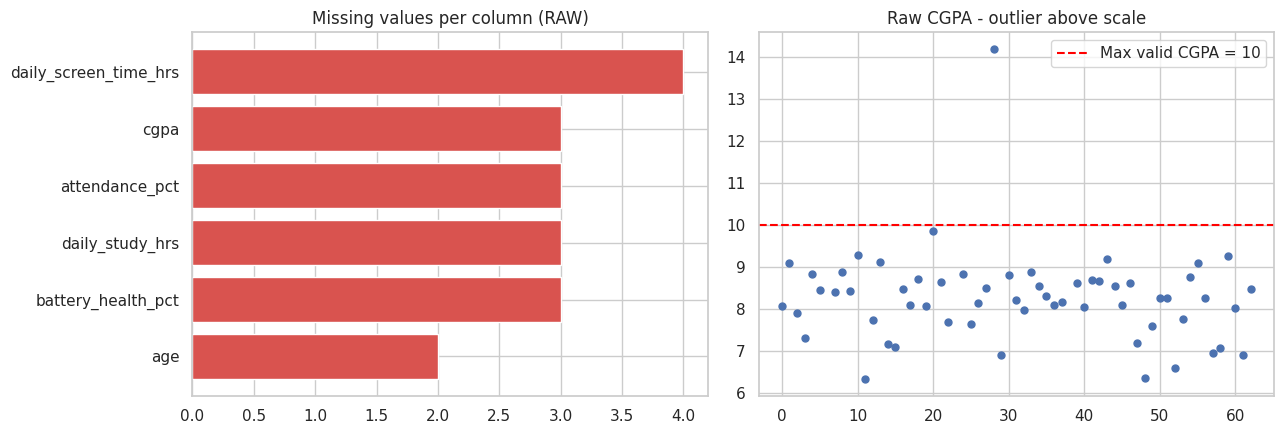

In [3]:
print("\nDuplicate rows:", raw.duplicated().sum())
print("Gender values:", raw["gender"].unique())
print("Overnight values:", raw["charges_overnight"].unique())
print("\nMissing values:\n", raw.isna().sum()[raw.isna().sum() > 0])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
m = raw.isna().sum(); m = m[m > 0].sort_values()
ax[0].barh(m.index, m.values, color="#d9534f"); ax[0].set_title("Missing values per column (RAW)")
ax[1].scatter(range(len(raw)), pd.to_numeric(raw["cgpa"], errors="coerce"), s=25)
ax[1].axhline(10, color="red", ls="--", label="Max valid CGPA = 10")
ax[1].set_title("Raw CGPA - outlier above scale"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Clean The Data

In [4]:
df = raw.drop_duplicates().copy()
df["gender"] = df["gender"].astype(str).str.strip().str.lower().str[0].map({"m": "Male", "f": "Female"})
df["charges_overnight"] = df["charges_overnight"].astype(str).str.strip().str.lower().str[0].map({"y": "Yes", "n": "No"})
num_cols = ["age", "daily_screen_time_hrs", "battery_health_pct", "daily_study_hrs", "cgpa", "attendance_pct"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(r"[^\d.]", "", regex=True), errors="coerce")
df.loc[(df.age < 15) | (df.age > 40), "age"] = np.nan
df.loc[df.daily_screen_time_hrs > 16, "daily_screen_time_hrs"] = np.nan
df.loc[df.battery_health_pct > 100, "battery_health_pct"] = np.nan
df.loc[df.cgpa > 10, "cgpa"] = np.nan
for c in num_cols:
    df[c] = df[c].fillna(df[c].median())
for c in ["age", "battery_health_pct", "attendance_pct"]:
    df[c] = df[c].round().astype(int)
df = df.sort_values("student_id").reset_index(drop=True)

print("\nCLEANED DATA:", df.shape, "| missing:", int(df.isna().sum().sum()))
display(df.head())
display(df.describe().round(2))


CLEANED DATA: (60, 11) | missing: 0


,student_id,age,gender,year_of_study,daily_screen_time_hrs,daily_charge_cycles,battery_health_pct,charges_overnight,daily_study_hrs,attendance_pct,cgpa
0,S001,17,Female,1,3.9,4,85,Yes,5.7,78,8.77
1,S002,23,Female,4,7.2,4,88,Yes,0.5,84,6.60
2,S003,22,Male,4,2.5,2,96,Yes,3.6,94,8.45
3,S004,20,Female,4,4.9,4,85,No,3.8,85,8.47
4,S005,20,Male,4,5.8,4,83,No,3.8,84,8.26


,age,daily_screen_time_hrs,battery_health_pct,daily_study_hrs,attendance_pct,cgpa
count,60.00,60.00,60.00,60.00,60.00,60.00
mean,20.70,5.04,85.68,3.66,82.02,8.16
std,2.21,1.31,7.54,1.38,8.80,0.76
min,17.00,2.40,69.00,0.50,61.00,6.32
25%,19.00,4.20,80.75,2.85,77.00,7.75
50%,21.00,4.90,85.00,3.80,84.00,8.26
75%,23.00,6.22,89.25,4.60,87.25,8.64
max,24.00,7.80,100.00,5.80,100.00,9.85


In [5]:
# Save original (raw) and cleaned data in one Excel workbook
with pd.ExcelWriter("Team 6 - original data ,cleaned data.xlsx") as writer:
    raw.to_excel(writer, sheet_name="Original Data", index=False)
    df.to_excel(writer, sheet_name="Cleaned Data", index=False)
print("Saved Excel workbook with sheets: Original Data, Cleaned Data")

Saved Excel workbook with sheets: Original Data, Cleaned Data


## 4. Visualizations

### 4a. Distributions

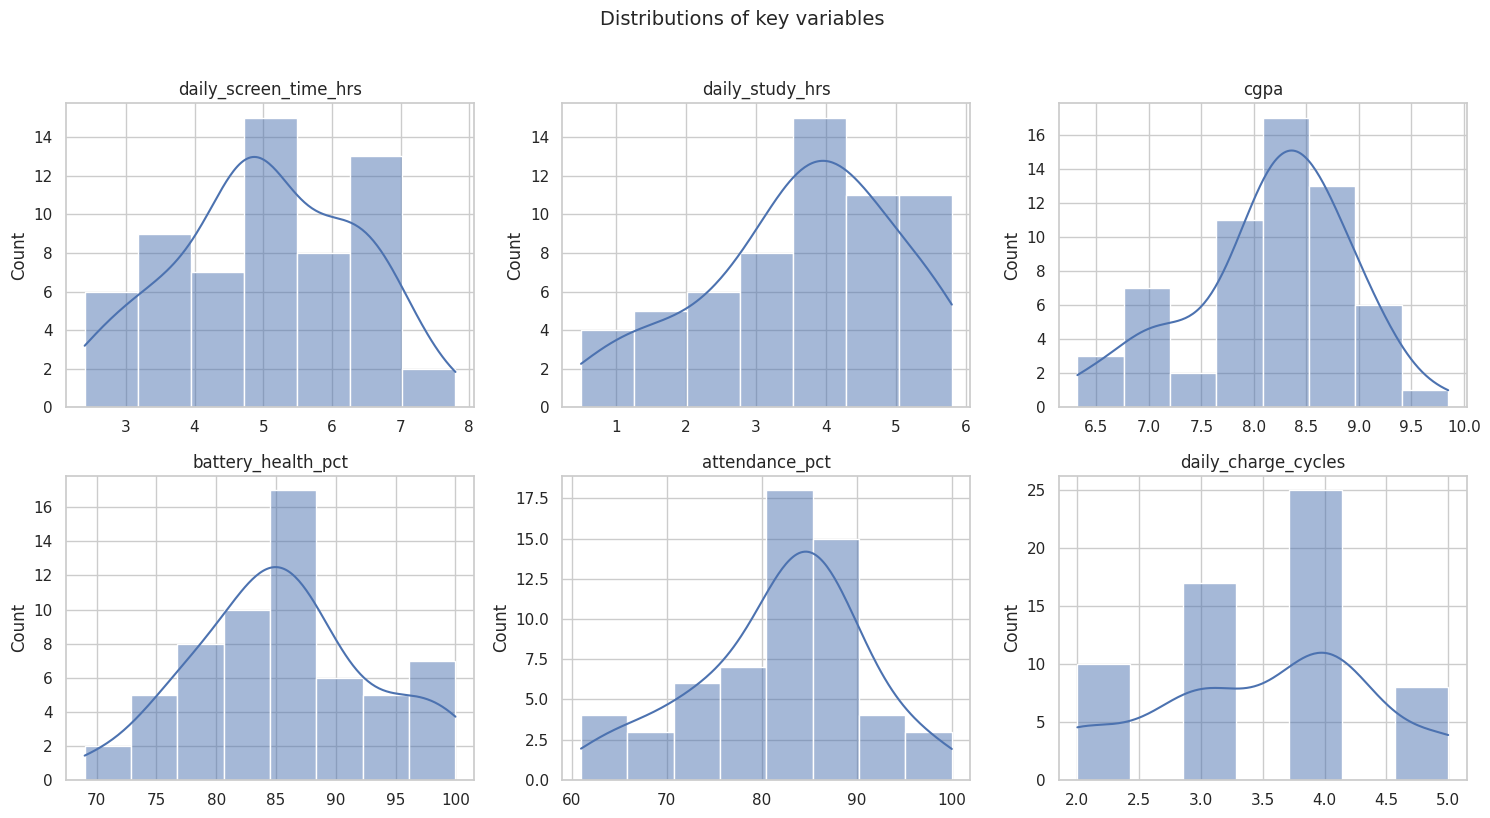

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols = ["daily_screen_time_hrs", "daily_study_hrs", "cgpa", "battery_health_pct", "attendance_pct", "daily_charge_cycles"]
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df[c], kde=True, ax=ax); ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Distributions of key variables", fontsize=14, y=1.02); plt.tight_layout(); plt.show()

### 4b. Category counts

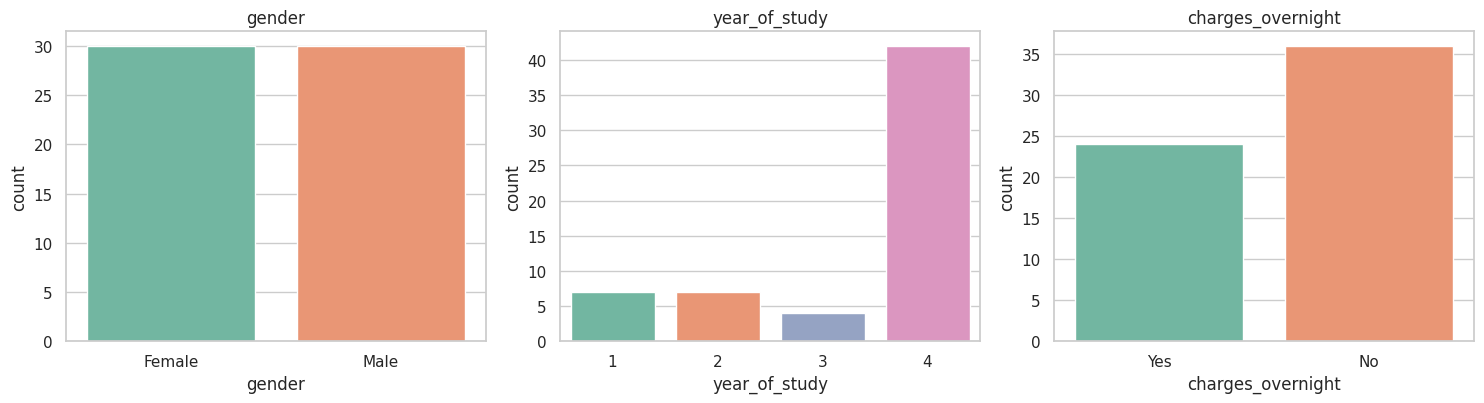

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, c in zip(axes, ["gender", "year_of_study", "charges_overnight"]):
    sns.countplot(data=df, x=c, ax=ax, palette="Set2"); ax.set_title(c)
plt.tight_layout(); plt.show()

### 4c. Correlation heatmap

Correlation with CGPA:
 daily_screen_time_hrs   -0.339
age                     -0.165
battery_health_pct       0.048
attendance_pct           0.160
daily_study_hrs          0.760
Name: cgpa, dtype: float64


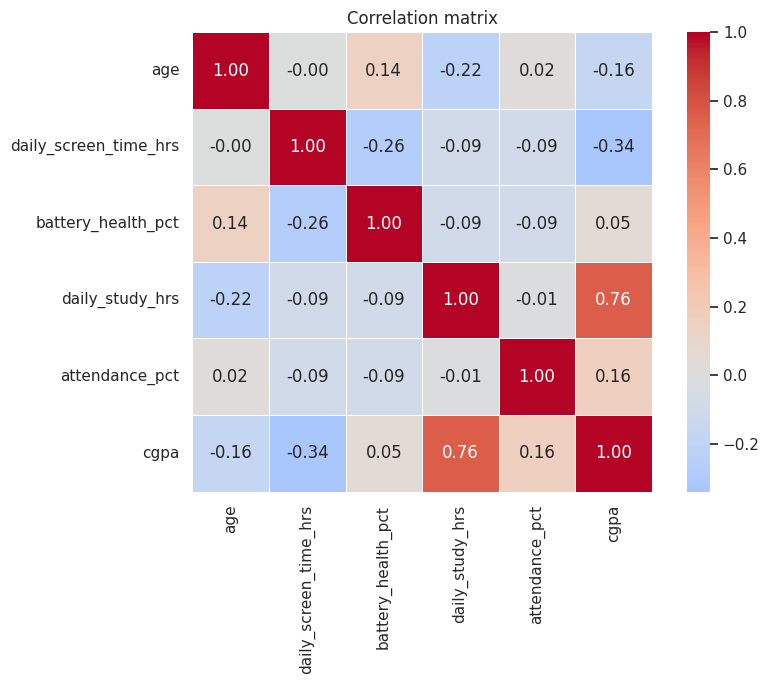

In [8]:
corr = df.select_dtypes("number").corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()
print("Correlation with CGPA:\n", corr["cgpa"].drop("cgpa").sort_values().round(3))

### 4d. Screen time & study time vs CGPA

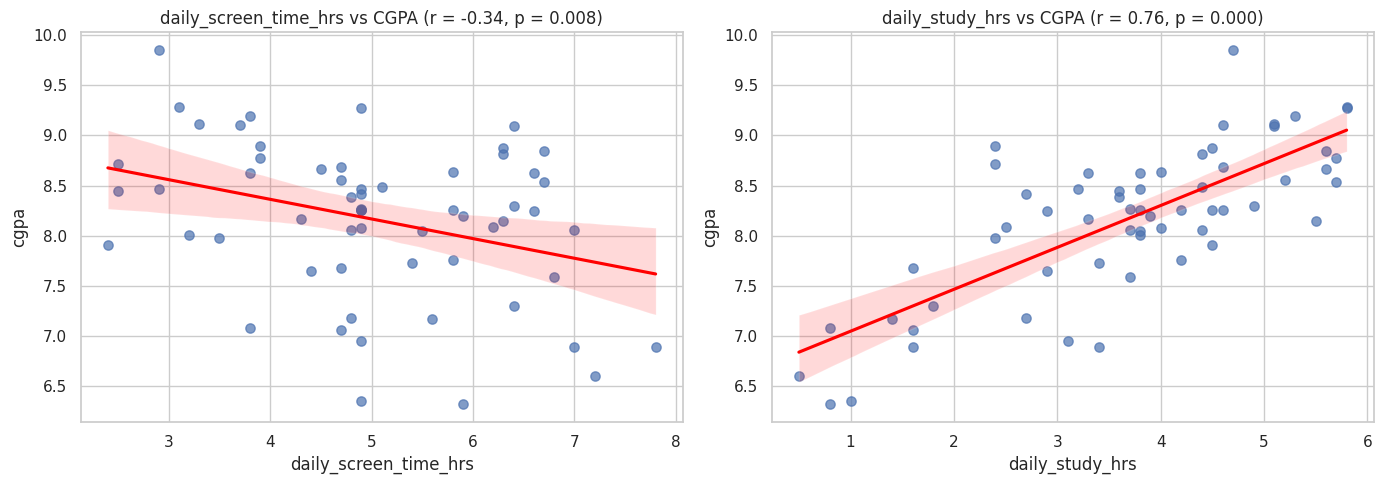

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, x in zip(axes, ["daily_screen_time_hrs", "daily_study_hrs"]):
    sns.regplot(data=df, x=x, y="cgpa", ax=ax, scatter_kws={"alpha": .7, "s": 45}, line_kws={"color": "red"})
    r, p = stats.pearsonr(df[x], df["cgpa"])
    ax.set_title(f"{x} vs CGPA (r = {r:.2f}, p = {p:.3f})")
plt.tight_layout(); plt.show()

### 4e. Battery & charging habits

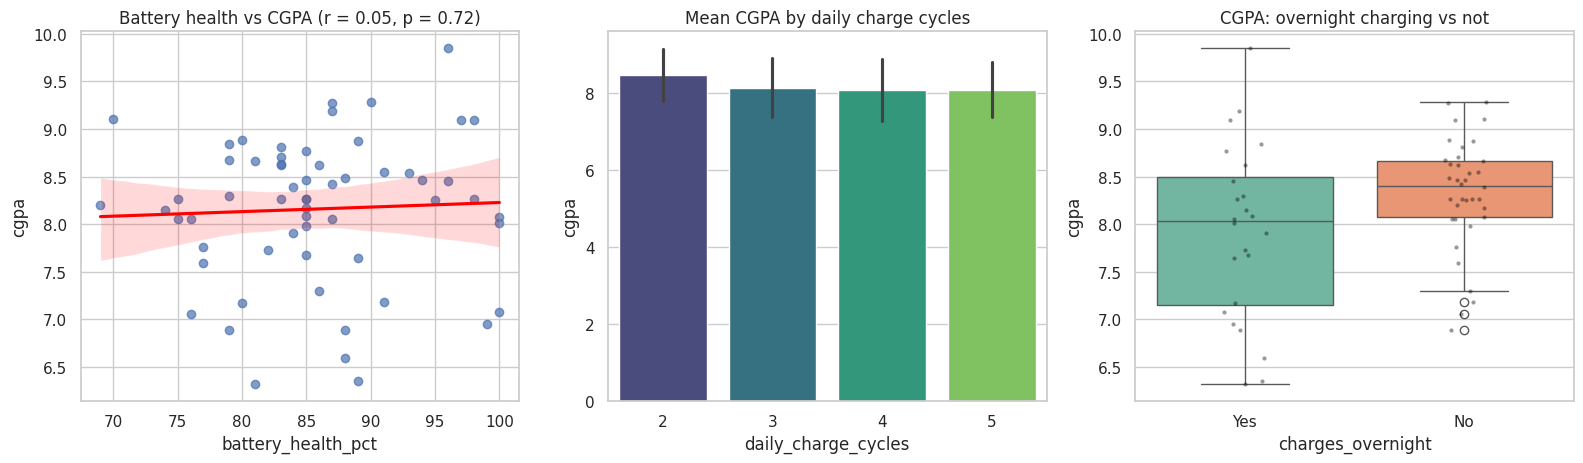

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.regplot(data=df, x="battery_health_pct", y="cgpa", ax=axes[0], scatter_kws={"alpha": .7}, line_kws={"color": "red"})
r, p = stats.pearsonr(df["battery_health_pct"], df["cgpa"])
axes[0].set_title(f"Battery health vs CGPA (r = {r:.2f}, p = {p:.2f})")
sns.barplot(data=df, x="daily_charge_cycles", y="cgpa", ax=axes[1], errorbar="sd", palette="viridis")
axes[1].set_title("Mean CGPA by daily charge cycles")
sns.boxplot(data=df, x="charges_overnight", y="cgpa", ax=axes[2], palette="Set2")
sns.stripplot(data=df, x="charges_overnight", y="cgpa", ax=axes[2], color="black", alpha=.4, size=3)
axes[2].set_title("CGPA: overnight charging vs not")
plt.tight_layout(); plt.show()

### 4f. Screen-time groups

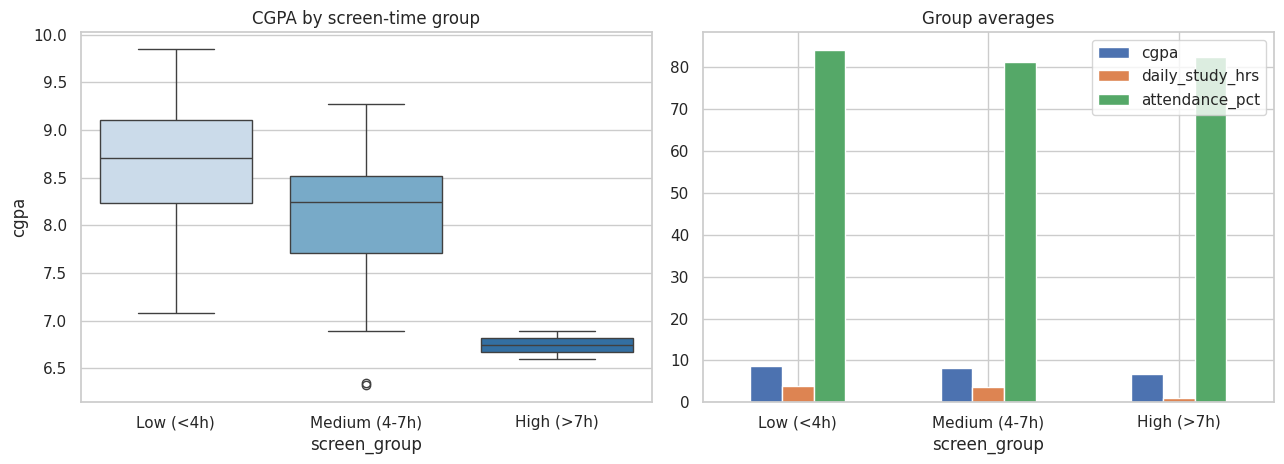

In [11]:
df["screen_group"] = pd.cut(df["daily_screen_time_hrs"], bins=[0, 4, 7, 12],
                            labels=["Low (<4h)", "Medium (4-7h)", "High (>7h)"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.boxplot(data=df, x="screen_group", y="cgpa", ax=axes[0], palette="Blues"); axes[0].set_title("CGPA by screen-time group")
grp = df.groupby("screen_group", observed=True)[["cgpa", "daily_study_hrs", "attendance_pct"]].mean()
grp.plot(kind="bar", ax=axes[1], rot=0); axes[1].set_title("Group averages")
plt.tight_layout(); plt.show()

### 4g. Pairplot

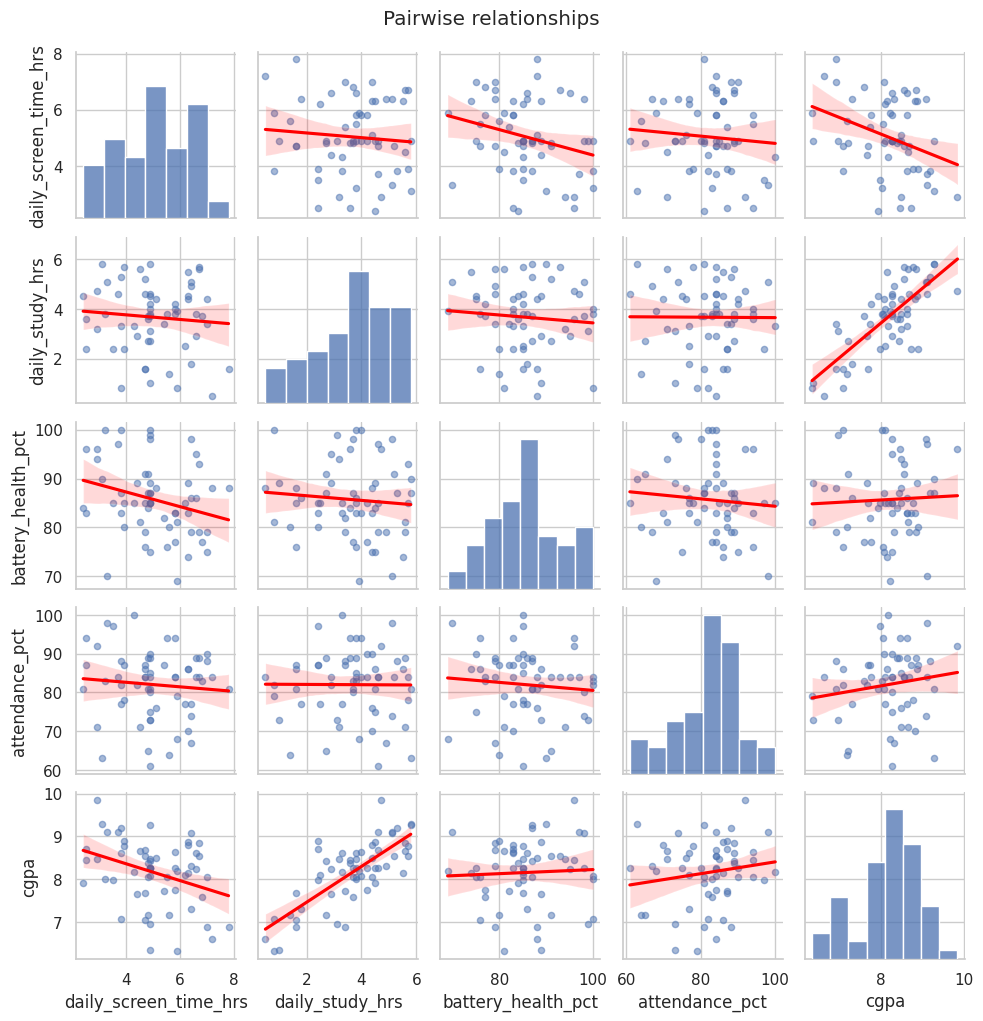

In [12]:
sns.pairplot(df[["daily_screen_time_hrs", "daily_study_hrs", "battery_health_pct", "attendance_pct", "cgpa"]],
             kind="reg", plot_kws={"line_kws": {"color": "red"}, "scatter_kws": {"alpha": .5, "s": 20}}, height=2)
plt.suptitle("Pairwise relationships", y=1.02); plt.show()

## 5. Statistical Tests & Regression


Overnight chargers mean CGPA = 7.92 | Others = 8.32 | Welch t = -1.91, p = 0.065
ANOVA across screen-time groups: F = 8.39, p = 0.0006

Regression R-squared = 0.677
daily_screen_time_hrs   -0.207
daily_charge_cycles      0.031
battery_health_pct       0.042
attendance_pct           0.118
daily_study_hrs          0.561
dtype: float64


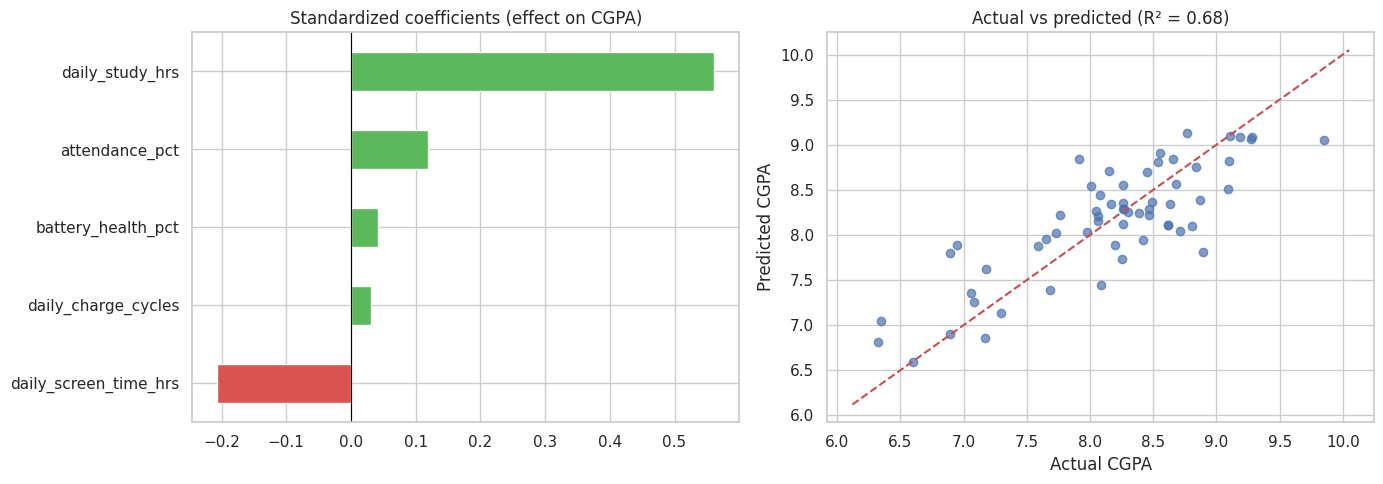

In [13]:
yes = df.loc[df.charges_overnight == "Yes", "cgpa"]; no = df.loc[df.charges_overnight == "No", "cgpa"]
t, p = stats.ttest_ind(yes, no, equal_var=False)
print(f"\nOvernight chargers mean CGPA = {yes.mean():.2f} | Others = {no.mean():.2f} | Welch t = {t:.2f}, p = {p:.3f}")
f, p2 = stats.f_oneway(*[g["cgpa"].values for _, g in df.groupby("screen_group", observed=True)])
print(f"ANOVA across screen-time groups: F = {f:.2f}, p = {p2:.4f}")

features = ["daily_screen_time_hrs", "daily_study_hrs", "battery_health_pct", "daily_charge_cycles", "attendance_pct"]
X = df[features].astype(float); Xs = (X - X.mean()) / X.std()
A = np.column_stack([np.ones(len(Xs)), Xs.values]); y = df["cgpa"].values
beta, *_ = np.linalg.lstsq(A, y, rcond=None); pred = A @ beta
r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
coef = pd.Series(beta[1:], index=features).sort_values()
print(f"\nRegression R-squared = {r2:.3f}\n{coef.round(3)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
coef.plot(kind="barh", ax=axes[0], color=["#d9534f" if v < 0 else "#5cb85c" for v in coef])
axes[0].axvline(0, color="black", lw=.8)
axes[0].set_title("Standardized coefficients (effect on CGPA)")
axes[1].scatter(y, pred, alpha=.7)
lims = [min(y.min(), pred.min()) - .2, max(y.max(), pred.max()) + .2]
axes[1].plot(lims, lims, "r--"); axes[1].set_xlabel("Actual CGPA"); axes[1].set_ylabel("Predicted CGPA")
axes[1].set_title(f"Actual vs predicted (R² = {r2:.2f})")
plt.tight_layout(); plt.show()

## 6. Model Comparison

We predict **CGPA** from the other variables. With only 60 students, models are judged with **5-fold cross-validation** (more reliable than a single split), plus a 80/20 hold-out test. A mean-only **Dummy baseline** shows what 'no skill' looks like (R-squared near 0).

In [14]:
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

ml = df.drop(columns=["student_id", "screen_group"]).copy()
ml["gender"] = (ml["gender"] == "Male").astype(int)
ml["charges_overnight"] = (ml["charges_overnight"] == "Yes").astype(int)
Xm, ym = ml.drop(columns="cgpa"), ml["cgpa"]

models = {
    "Dummy (mean baseline)": DummyRegressor(),
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=3.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=4, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=42),
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.2, random_state=42)

rows = []
for name, mdl in models.items():
    s = cross_validate(mdl, Xm, ym, cv=cv, scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"))
    mdl.fit(Xtr, ytr); pr = mdl.predict(Xte)
    rows.append({"Model": name,
                 "CV_R2_mean": s["test_r2"].mean(), "CV_R2_std": s["test_r2"].std(),
                 "CV_RMSE": -s["test_neg_root_mean_squared_error"].mean(),
                 "CV_MAE": -s["test_neg_mean_absolute_error"].mean(),
                 "Test_R2": r2_score(yte, pr),
                 "Test_RMSE": mean_squared_error(yte, pr) ** 0.5})
comparison = pd.DataFrame(rows).sort_values("CV_R2_mean", ascending=False).reset_index(drop=True).round(3)
comparison.to_csv("model_comparison.csv", index=False)
comparison

,Model,CV_R2_mean,CV_R2_std,CV_RMSE,CV_MAE,Test_R2,Test_RMSE
0,Ridge Regression,0.467,0.390,0.455,0.371,0.631,0.406
1,Linear Regression,0.451,0.412,0.460,0.374,0.622,0.411
2,Random Forest,0.434,0.293,0.490,0.402,0.474,0.485
3,Gradient Boosting,0.358,0.496,0.490,0.397,0.441,0.500
4,Dummy (mean baseline),-0.228,0.423,0.748,0.588,-0.019,0.674


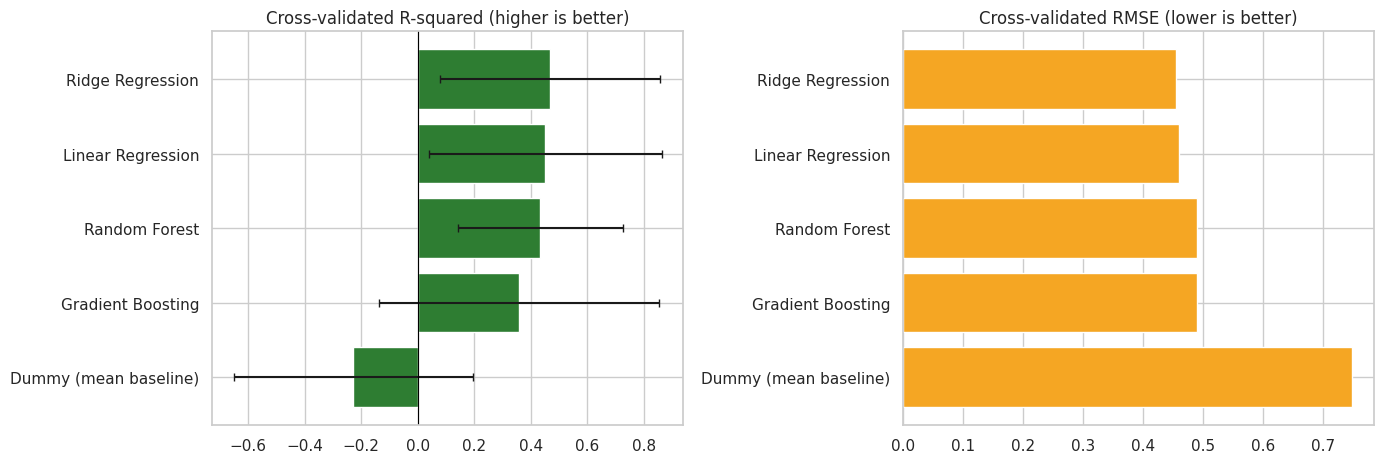

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
order = comparison.sort_values("CV_R2_mean")
axes[0].barh(order["Model"], order["CV_R2_mean"], xerr=order["CV_R2_std"], color="#2e7d32", capsize=3)
axes[0].axvline(0, color="black", lw=.8); axes[0].set_title("Cross-validated R-squared (higher is better)")
order = comparison.sort_values("CV_RMSE", ascending=False)
axes[1].barh(order["Model"], order["CV_RMSE"], color="#f5a623")
axes[1].set_title("Cross-validated RMSE (lower is better)")
plt.tight_layout(); plt.show()

Best model by cross-validated R-squared: Ridge Regression


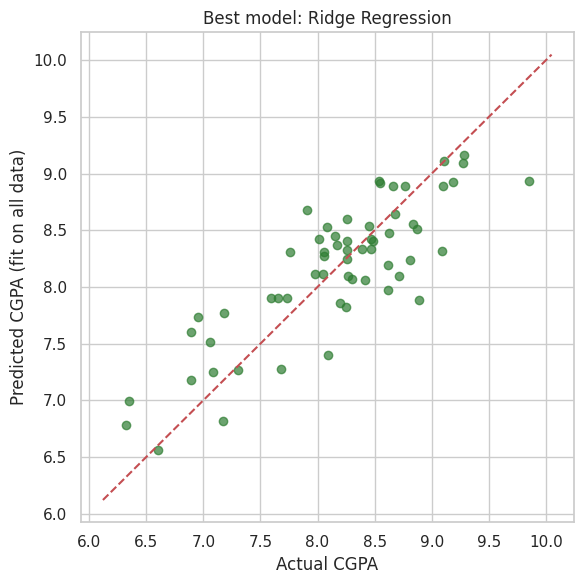

In [16]:
best_name = comparison.iloc[0]["Model"]
best = models[best_name].fit(Xm, ym)
plt.figure(figsize=(6, 6))
plt.scatter(ym, best.predict(Xm), alpha=.7, color="#2e7d32")
lims = [ym.min() - .2, ym.max() + .2]; plt.plot(lims, lims, "r--")
plt.xlabel("Actual CGPA"); plt.ylabel("Predicted CGPA (fit on all data)")
plt.title(f"Best model: {best_name}"); plt.tight_layout(); plt.show()
print("Best model by cross-validated R-squared:", best_name)

## 7. Feature Importance

Three views of which features matter: **Random Forest importance**, **permutation importance** (how much the error grows when a feature is shuffled) and **standardized linear coefficients** (direction of the effect).

In [17]:
from sklearn.inspection import permutation_importance

rf = RandomForestRegressor(n_estimators=300, max_depth=4, random_state=42).fit(Xm, ym)
perm = permutation_importance(rf, Xm, ym, n_repeats=30, random_state=42)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xm, ym)

fi = pd.DataFrame({
    "Feature": Xm.columns,
    "RF_Importance": rf.feature_importances_,
    "Permutation_Importance": perm.importances_mean,
    "Linear_Std_Coefficient": lin[-1].coef_,
}).sort_values("RF_Importance", ascending=False).reset_index(drop=True).round(3)
fi.to_csv("feature_importance.csv", index=False)
fi

,Feature,RF_Importance,Permutation_Importance,Linear_Std_Coefficient
0,daily_study_hrs,0.726,1.254,0.532
1,daily_screen_time_hrs,0.101,0.107,-0.175
2,battery_health_pct,0.052,0.044,0.081
3,attendance_pct,0.046,0.040,0.119
4,age,0.031,0.021,-0.090
5,daily_charge_cycles,0.017,0.012,0.002
6,charges_overnight,0.016,0.020,-0.128
7,gender,0.007,0.003,-0.011
8,year_of_study,0.004,0.002,0.065


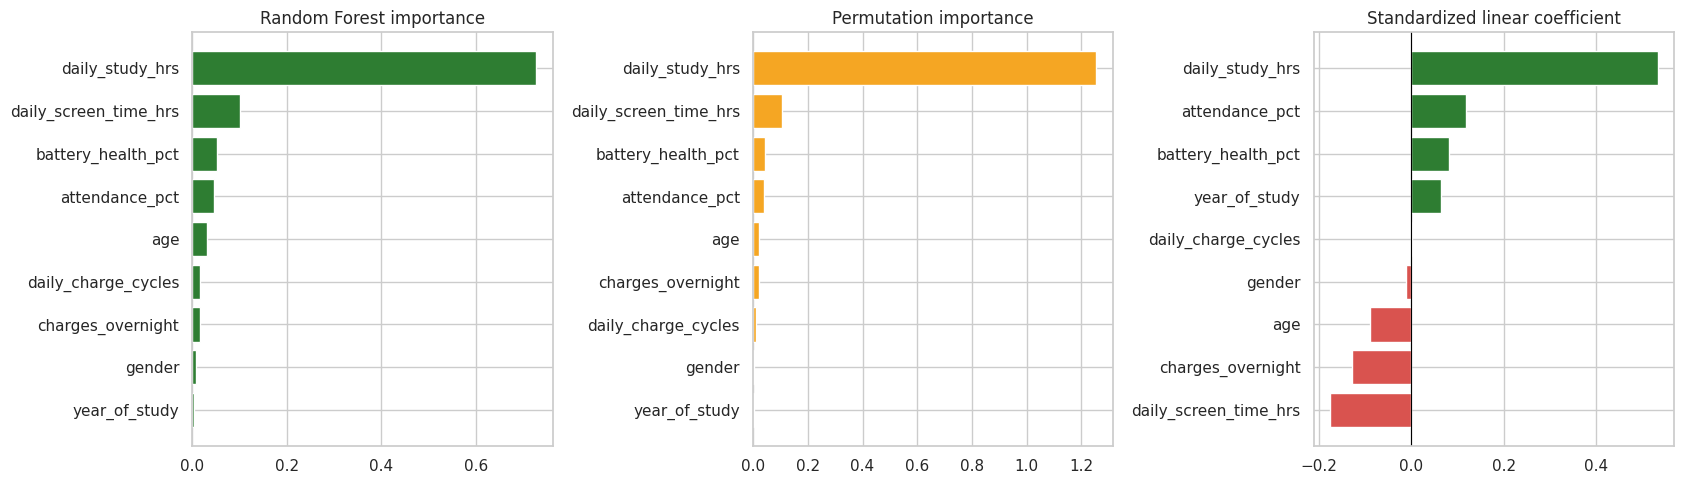

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
o = fi.sort_values("RF_Importance")
axes[0].barh(o["Feature"], o["RF_Importance"], color="#2e7d32"); axes[0].set_title("Random Forest importance")
o = fi.sort_values("Permutation_Importance")
axes[1].barh(o["Feature"], o["Permutation_Importance"], color="#f5a623"); axes[1].set_title("Permutation importance")
o = fi.sort_values("Linear_Std_Coefficient")
axes[2].barh(o["Feature"], o["Linear_Std_Coefficient"], color=["#d9534f" if v < 0 else "#2e7d32" for v in o["Linear_Std_Coefficient"]])
axes[2].axvline(0, color="black", lw=.8); axes[2].set_title("Standardized linear coefficient")
plt.tight_layout(); plt.show()

## 8. Conclusions

- **Study time** is the strongest driver of CGPA (top feature: `daily_study_hrs`); screen time has a clear negative effect.
- **Battery health** and **charge cycles** add almost nothing once study time and screen time are known - battery condition does not predict grades.
- **Best model:** Ridge Regression (cross-validated R-squared = 0.47, RMSE = 0.46 CGPA points). All real models clearly beat the mean-only baseline.
- Simple linear models do about as well as tree models here, which fits how the data behaves: the relationships are roughly linear.
- **Limitations:** only 60 synthetic students, so results demonstrate the workflow rather than describe real students. Correlation is not causation.